# 006. Model/Data Drift Detection and Mitigation

## Simplified Overview

Models degrade over time as the world changes. Users' preferences shift, exploited vulnerabilities follow new patterns, or data quality changes. Drift detection monitors whether model performance has declined, while mitigation strategies—retraining, adaptive weights, online learning—keep the model current.

## Technical Overview

* **Data Drift**: Distribution of input features P(X) changes
* **Label Drift**: Distribution of targets P(Y) changes
* **Concept Drift**: Relationship P(Y|X) changes (models detect this)
* **Covariate Shift**: P(X) changes but P(Y|X) unchanged (easier to handle)

Detection methods:
* **Holdout testing**: Compare current performance against historical baseline
* **Statistical tests**: Kolmogorov-Smirnov (KS), Hellinger distance, Maximum Mean Discrepancy (MMD)
* **Supervised drift**: Train "drift detector" binary classifier on (historical, current) data
* **Model-based**: Monitor prediction uncertainty, calibration, or feature distributions

## Detailed Explanation

### Detection Strategies

#### 1. Performance-Based Detection
```
Track metric over time: M_t = f1_score, auc, calibration_error(t)

Alert if:
  |M_t - M_baseline| > threshold  (for recent window)
  OR trend(M_t) significantly negative
```

#### 2. Statistical Distribution Tests
```
H₀: P_current(X) = P_baseline(X)
Test statistics: KS statistic, Hellinger distance, JS divergence

KS = max_x |F_baseline(x) - F_current(x)|

Reject H₀ if KS > critical value → evidence of drift
```

#### 3. Supervised Drift Detection (ADWIN variant)
```
Train binary classifier:
  Class 0: samples from baseline period
  Class 1: samples from recent period

If classifier achieves AUC > 0.6 (better than random) → drift detected
AUC magnitude indicates drift severity
```

#### 4. Prediction Uncertainty Monitoring
```
Track: mean prediction entropy, variance of predictions

Drift signal:
  - Entropy spike: model increasingly uncertain
  - Calibration degradation: confidence ≠ accuracy
  - Feature importance shifts: new features dominate
```

### Mitigation Strategies

| Strategy | Trigger | Cost | Best For |
| :--- | :---: | :---: | :---: |
| Retraining | Performance below threshold | High (new labels needed) | Severe drift; available labels |
| Reweighting | Covariate shift detected | Low (no new labels) | Shift in feature distribution |
| Online Learning | Continuous drift | Medium (streaming labels) | Non-stationary environments |
| Threshold Tuning | Concept drift in minority class | Low (no retraining) | Imbalanced settings |
| Ensemble Rotation | Gradual drift | Medium | Model diversity |

## Python Libraries
| Library | Purpose |
| :--- | :---: |
| `river`| Online machine learning; streaming data |
| `alibi-detect`| Drift detection for features and predictions |
| `evidently`| ML model monitoring and drift detection dashboards |
| `scikit-learn`| Baseline models with sample_weight for reweighting |
| `scipy.stats`| KS test, distribution comparison |

## References

* Gama, J., et al. (2014). "Learning from Streaming Data: Concepts, Algorithms, and Evaluations." _Journal of Machine Learning Research_, **15**, 49-76.
* Bifet, A., & Gavalda, R. (2007). "Learning from Time-changing Data with Adaptive Windowing." _SIAM International Conference on Data Mining_, 443-448.
* Montiel, J., et al. (2021). "River: Machine Learning for Streaming Data." _Journal of Machine Learning Research_, **22**(110), 1-8.

## Python Implementation Examples

### Imporation of Requisite Python Modules

In [1]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, log_loss, accuracy_score
from scipy.stats import ks_2samp
from scipy.spatial.distance import jensenshannon
import matplotlib.pyplot as plt

### Example: EPSS Exploitation Prediction Model Drift Over Time

In [2]:
np.random.seed(42)

In [3]:
# ============================================================================
# PART 1: Simulate time-series data with concept drift
# ============================================================================

# Baseline period (Jan 2024): features and model are stable
n_baseline = 500
X_baseline = np.random.randn(n_baseline, 5)
y_baseline = (X_baseline[:, 0] + X_baseline[:, 1] - X_baseline[:, 2] > 0).astype(int)

print(f"Baseline period: {n_baseline} CVEs")
print(f"  Exploitation rate: {y_baseline.mean():.2%}")

# Simulate 6 months of new CVEs with gradual concept drift
n_periods = 6
n_per_period = 200
timeline = []
drift_magnitudes = []

# Drift: The relationship between features and exploitation changes
# e.g., old exploit vectors become less relevant, new attack methods emerge

for period in range(n_periods):
    # Gradually shift feature distribution + change decision boundary
    shift_factor = 0.15 * period  # Accumulating shift
    
    X_period = np.random.randn(n_per_period, 5) + shift_factor
    
    # New decision boundary (concept drift): feature importance shifts
    if period < 2:
        # Original relationship
        y_period = (X_period[:, 0] + X_period[:, 1] - X_period[:, 2] > 0).astype(int)
    else:
        # Concept drift: different features now predictive
        y_period = (X_period[:, 1] + X_period[:, 2] + 0.5 * X_period[:, 3] > 0).astype(int)
    
    timeline.append({
        'period': period,
        'X': X_period,
        'y': y_period,
        'exploitation_rate': y_period.mean()
    })
    
    drift_magnitudes.append(shift_factor)

print(f"\nTest periods (Jan 2024 - Jun 2024): {n_periods} months")
for t in timeline:
    print(f"  Period {t['period']}: exploitation rate {t['exploitation_rate']:.2%}")

Baseline period: 500 CVEs
  Exploitation rate: 49.80%

Test periods (Jan 2024 - Jun 2024): 6 months
  Period 0: exploitation rate 52.00%
  Period 1: exploitation rate 50.50%
  Period 2: exploitation rate 69.00%
  Period 3: exploitation rate 74.00%
  Period 4: exploitation rate 84.50%
  Period 5: exploitation rate 89.00%


In [4]:
# ============================================================================
# PART 2: Train baseline model and track performance over time
# ============================================================================

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_baseline_scaled = scaler.fit_transform(X_baseline)

# Train model on baseline
baseline_model = LogisticRegression(random_state=42, max_iter=1000)
baseline_model.fit(X_baseline_scaled, y_baseline)

print("\nBaseline model trained")
print(f"  Baseline AUC (on baseline test): {roc_auc_score(y_baseline, baseline_model.predict_proba(X_baseline_scaled)[:, 1]):.4f}")



Baseline model trained
  Baseline AUC (on baseline test): 0.9991


In [5]:
# ============================================================================
# Track performance and drift over time
# ============================================================================

performance_log = {
    'period': [],
    'auc': [],
    'accuracy': [],
    'log_loss_val': [],
    'mean_prediction_entropy': [],
    'ks_statistic': [],
    'detected_drift': []
}

auc_threshold = 0.65  # Alert if AUC drops below this
ks_threshold = 0.15   # KS statistic threshold for drift

for t_data in timeline:
    period = t_data['period']
    X_period = t_data['X']
    y_period = t_data['y']
    
    # Scale using baseline scaler
    X_period_scaled = scaler.transform(X_period)
    
    # Model predictions
    y_pred_proba = baseline_model.predict_proba(X_period_scaled)[:, 1]
    y_pred = (y_pred_proba >= 0.5).astype(int)
    
    # Performance metrics
    auc = roc_auc_score(y_period, y_pred_proba)
    acc = accuracy_score(y_period, y_pred)
    loss = log_loss(y_period, y_pred_proba)
    
    # Prediction entropy (uncertainty)
    entropy = -np.mean([
        y_pred_proba * np.log(y_pred_proba + 1e-10) +
        (1 - y_pred_proba) * np.log(1 - y_pred_proba + 1e-10)
    ])
    
    # Statistical drift: KS test on feature distributions
    # Compare X_period to X_baseline (average across features)
    ks_stats = []
    for feat_idx in range(X_period.shape[1]):
        ks_stat, _ = ks_2samp(X_baseline_scaled[:, feat_idx], X_period_scaled[:, feat_idx])
        ks_stats.append(ks_stat)
    
    ks_statistic = np.mean(ks_stats)
    
    # Drift detection: flag if performance drops or KS statistic high
    drift_detected = (auc < auc_threshold) or (ks_statistic > ks_threshold)
    
    performance_log['period'].append(period)
    performance_log['auc'].append(auc)
    performance_log['accuracy'].append(acc)
    performance_log['log_loss_val'].append(loss)
    performance_log['mean_prediction_entropy'].append(entropy)
    performance_log['ks_statistic'].append(ks_statistic)
    performance_log['detected_drift'].append(drift_detected)
    
    print(f"\nPeriod {period}:")
    print(f"  AUC: {auc:.4f} {'⚠️ LOW' if auc < auc_threshold else '✓'}")
    print(f"  Accuracy: {acc:.4f}")
    print(f"  Log Loss: {loss:.4f}")
    print(f"  Mean Entropy: {entropy:.4f}")
    print(f"  KS Statistic: {ks_statistic:.4f} {'⚠️ DRIFT' if ks_statistic > ks_threshold else '✓'}")
    print(f"  → Drift Detected: {drift_detected}")


Period 0:
  AUC: 0.9999 ✓
  Accuracy: 0.9900
  Log Loss: 0.0867
  Mean Entropy: 0.1659
  KS Statistic: 0.0606 ✓
  → Drift Detected: False

Period 1:
  AUC: 0.9992 ✓
  Accuracy: 0.9950
  Log Loss: 0.0793
  Mean Entropy: 0.1668
  KS Statistic: 0.0890 ✓
  → Drift Detected: False

Period 2:
  AUC: 0.4363 ⚠️ LOW
  Accuracy: 0.4850
  Log Loss: 3.0082
  Mean Entropy: 0.1667
  KS Statistic: 0.1356 ✓
  → Drift Detected: True

Period 3:
  AUC: 0.4893 ⚠️ LOW
  Accuracy: 0.5500
  Log Loss: 2.6828
  Mean Entropy: 0.1710
  KS Statistic: 0.1806 ⚠️ DRIFT
  → Drift Detected: True

Period 4:
  AUC: 0.4730 ⚠️ LOW
  Accuracy: 0.5600
  Log Loss: 2.3031
  Mean Entropy: 0.1819
  KS Statistic: 0.2384 ⚠️ DRIFT
  → Drift Detected: True

Period 5:
  AUC: 0.6637 ✓
  Accuracy: 0.7200
  Log Loss: 1.4546
  Mean Entropy: 0.1512
  KS Statistic: 0.3028 ⚠️ DRIFT
  → Drift Detected: True


In [6]:
# ============================================================================
# PART 3: Mitigation Strategies
# ============================================================================

print("\n" + "="*60)
print("MITIGATION: Retraining Strategy")
print("="*60)

# Strategy: Retrain when drift detected
model_history = [baseline_model]
retrain_periods = []

for i, is_drift in enumerate(performance_log['detected_drift']):
    if is_drift and i > 0:  # Don't retrain on first period
        print(f"\nPeriod {i}: Drift detected! Retraining model...")
        
        # Retrain on baseline + recent data
        X_retrain = np.vstack([
            X_baseline_scaled,
            scaler.transform(timeline[i]['X'])
        ])
        y_retrain = np.hstack([
            y_baseline,
            timeline[i]['y']
        ])
        
        retrained_model = LogisticRegression(random_state=42, max_iter=1000)
        retrained_model.fit(X_retrain, y_retrain)
        model_history.append(retrained_model)
        retrain_periods.append(i)
        
        # Evaluate retrained model on current period
        X_next_period = scaler.transform(timeline[i]['X'])
        y_next_period = timeline[i]['y']
        auc_retrained = roc_auc_score(y_next_period, retrained_model.predict_proba(X_next_period)[:, 1])
        print(f"  Retrained model AUC: {auc_retrained:.4f}")

print(f"\nRetrained in periods: {retrain_periods}")


MITIGATION: Retraining Strategy

Period 2: Drift detected! Retraining model...
  Retrained model AUC: 0.6297

Period 3: Drift detected! Retraining model...
  Retrained model AUC: 0.6499

Period 4: Drift detected! Retraining model...
  Retrained model AUC: 0.6520

Period 5: Drift detected! Retraining model...
  Retrained model AUC: 0.7972

Retrained in periods: [2, 3, 4, 5]



Plots generated (conceptual)


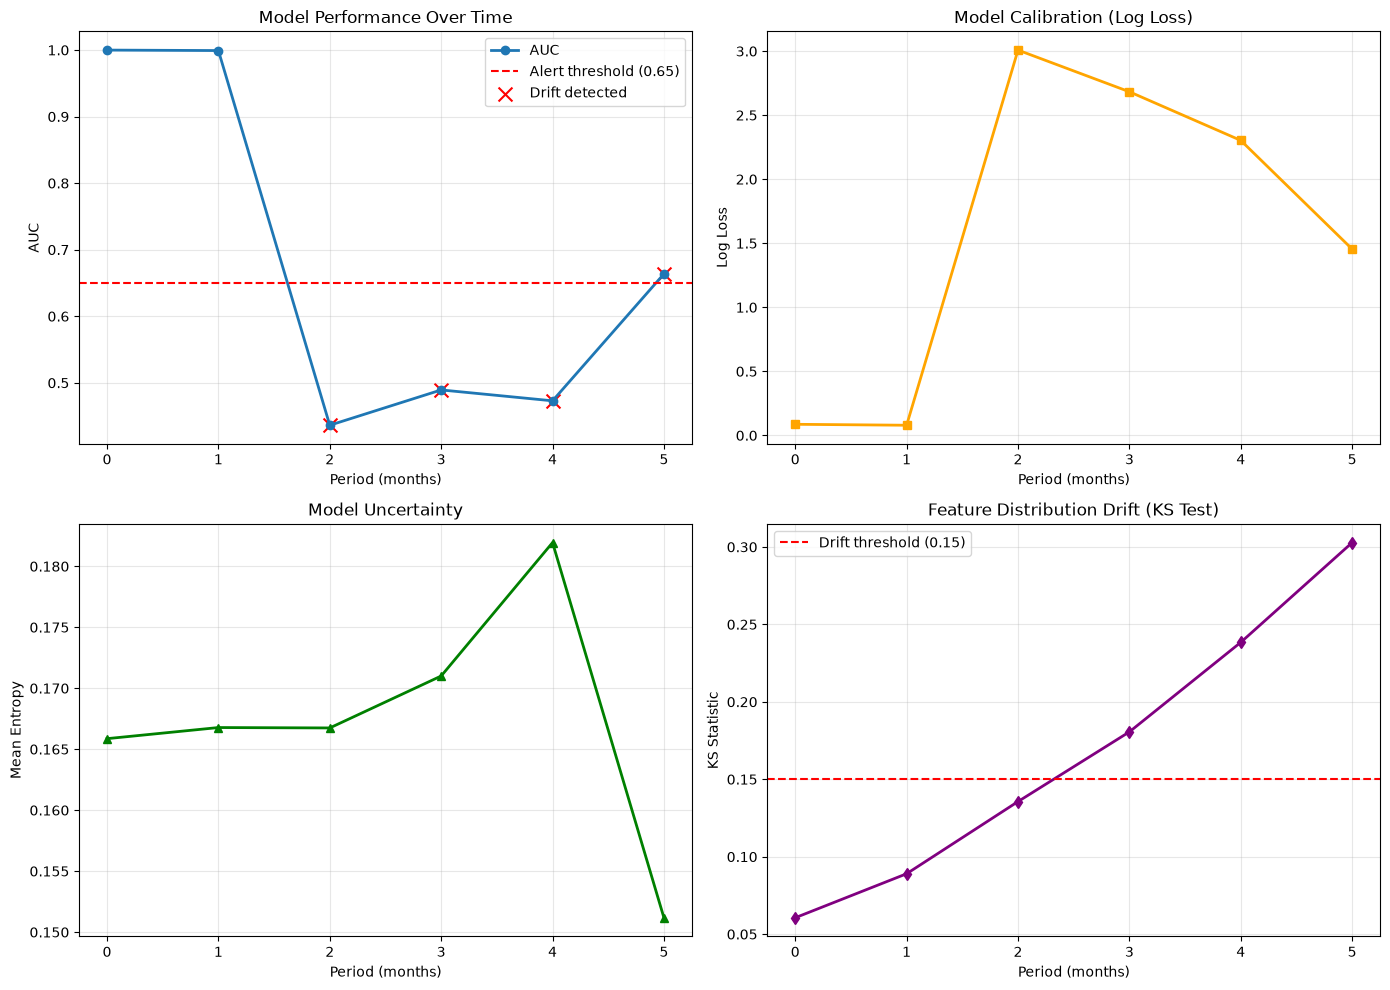

In [7]:
# ============================================================================
# PART 4: Visualization
# ============================================================================

df_perf = pd.DataFrame(performance_log)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: AUC Over Time
ax = axes[0, 0]
ax.plot(df_perf['period'], df_perf['auc'], marker='o', label='AUC', linewidth=2)
ax.axhline(auc_threshold, color='red', linestyle='--', label=f'Alert threshold ({auc_threshold})')
drift_periods = df_perf[df_perf['detected_drift']]['period']
ax.scatter(drift_periods, df_perf.loc[drift_periods, 'auc'], color='red', s=100, marker='x', label='Drift detected')
ax.set_xlabel('Period (months)')
ax.set_ylabel('AUC')
ax.set_title('Model Performance Over Time')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 2: Log Loss (Calibration)
ax = axes[0, 1]
ax.plot(df_perf['period'], df_perf['log_loss_val'], marker='s', color='orange', linewidth=2)
ax.set_xlabel('Period (months)')
ax.set_ylabel('Log Loss')
ax.set_title('Model Calibration (Log Loss)')
ax.grid(True, alpha=0.3)

# Plot 3: Prediction Entropy
ax = axes[1, 0]
ax.plot(df_perf['period'], df_perf['mean_prediction_entropy'], marker='^', color='green', linewidth=2)
ax.set_xlabel('Period (months)')
ax.set_ylabel('Mean Entropy')
ax.set_title('Model Uncertainty')
ax.grid(True, alpha=0.3)

# Plot 4: KS Statistic (Drift Detection)
ax = axes[1, 1]
ax.plot(df_perf['period'], df_perf['ks_statistic'], marker='d', color='purple', linewidth=2)
ax.axhline(ks_threshold, color='red', linestyle='--', label=f'Drift threshold ({ks_threshold})')
ax.set_xlabel('Period (months)')
ax.set_ylabel('KS Statistic')
ax.set_title('Feature Distribution Drift (KS Test)')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
print("\nPlots generated (conceptual)")

In [8]:
# ============================================================================
# PART 5: Online Learning (Adaptive Reweighting)
# ============================================================================

print("\n" + "="*60)
print("MITIGATION: Online Learning / Adaptive Weighting")
print("="*60)

# Strategy: Weight recent data higher in loss function
alpha = 0.95  # Exponential decay weight (older data downweighted)

online_aucs = []

for i, t_data in enumerate(timeline):
    X_online_train = np.vstack([
        X_baseline_scaled,
        *[scaler.transform(timeline[j]['X']) for j in range(i + 1)]
    ])
    y_online_train = np.hstack([
        y_baseline,
        *[timeline[j]['y'] for j in range(i + 1)]
    ])
    
    # Sample weights: decay older data
    n_baseline = len(y_baseline)
    weights = np.ones(len(y_online_train))
    weights[:n_baseline] = alpha ** i  # Baseline data downweighted exponentially
    
    # Normalize weights
    weights /= weights.sum() * len(weights)
    
    # Train with sample weights
    online_model = LogisticRegression(random_state=42, max_iter=1000)
    online_model.fit(X_online_train, y_online_train, sample_weight=weights)
    
    # Evaluate on current period
    X_test = scaler.transform(t_data['X'])
    y_test = t_data['y']
    auc_online = roc_auc_score(y_test, online_model.predict_proba(X_test)[:, 1])
    online_aucs.append(auc_online)
    
    print(f"Period {i}: Online model AUC = {auc_online:.4f}")

print("\nComparison:")
print(f"  Static model AUC (mean): {np.mean(performance_log['auc']):.4f}")
print(f"  Online model AUC (mean): {np.mean(online_aucs):.4f}")


MITIGATION: Online Learning / Adaptive Weighting
Period 0: Online model AUC = 0.9997
Period 1: Online model AUC = 0.9980
Period 2: Online model AUC = 0.5276
Period 3: Online model AUC = 0.6645
Period 4: Online model AUC = 0.7725
Period 5: Online model AUC = 0.9443

Comparison:
  Static model AUC (mean): 0.6769
  Online model AUC (mean): 0.8178
